# 01 · Causalidade de Granger por UF e tipologia

**Etapa 1 — notebook principal, completo e reproduzível.** Estuda se as defasagens de desastres contribuem para prever mudanças na inadimplência além do histórico da própria inadimplência. **Causalidade de Granger é precedência preditiva, não identificação causal.**

**Estrutura:** 27 UFs × 2 períodos (pré-pandemia: até jan/2020; total: até dez/2024) × **16 tipologias originais do Atlas** = 864 aplicações planejadas. Não usamos grupos de desastres. A base mensal consolidada (2013–2024, 3.888 linhas) não é enviada ao GitHub; obtenha-a segundo `data/README.md`.

**Roteiro executável:** (1) integridade e transformação → (2) inspeção de estacionariedade → (3) suporte e BIC com lags 1–6 → (4) teste F e BH local → (5) Ljung–Box e magnitude da autocorrelação → (6) tabelas, gráficos, interpretação e limites.

O notebook contém as funções efetivas de cálculo: **não depende de `src/` para realizar a análise**. Evite rodá-lo em paralelo aos outros notebooks, pois os diretórios de tabelas são compartilhados.

## 1. Dependências e proveniência

Instale `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib` e `ipykernel` (ver `requirements-revisao-estadual.txt`). Confira que `data/processed/df_tcc_2013_2024.csv` é a mesma base auditada pelo hash SHA-256.

In [1]:
from pathlib import Path
import hashlib, os, warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import acorr_ljungbox

# Executável a partir da raiz do repositório ou da pasta notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT=ROOT.parent
if not (ROOT/'data').exists():
    raise FileNotFoundError('Execute a partir da raiz do repositório ou de notebooks/.')
BASE = Path(os.environ.get('TCC_BASE_CSV',str(ROOT/'data/processed/df_tcc_2013_2024.csv')))
if not BASE.exists():
    raise FileNotFoundError(f'Base mensal não versionada: {BASE}. Consulte data/README.md.')
EXPECTED_HASH='46f4f8408f5f6a809de2601b5c313ea52ee5992ed5a65ede5246c57d28767e36'
actual_sha=hashlib.sha256(BASE.read_bytes()).hexdigest()
assert actual_sha==EXPECTED_HASH, f'Hash da base diferente do painel auditado: {actual_sha}'
SOURCE=BASE
OUT=ROOT/'outputs/tables/revisao_estadual_20261019'
AUD=ROOT/'outputs/tables/auditoria_metodologica_20261020'
OUT.mkdir(parents=True,exist_ok=True)
AUD.mkdir(parents=True,exist_ok=True)
TIPOS=['tipo_alagamentos','tipo_chuvas_intensas','tipo_doencas_infecciosas','tipo_enxurradas','tipo_erosao','tipo_estiagem_e_seca','tipo_granizo','tipo_incendio_florestal','tipo_inundacoes','tipo_movimento_de_massa','tipo_onda_de_calor_e_baixa_umidade','tipo_onda_de_frio','tipo_outros','tipo_rompimento_colapso_de_barragens','tipo_tornado','tipo_vendavais_e_ciclones']
print('Base auditada:',BASE.name,'| SHA-256:',actual_sha[:16]+'…')

Base auditada: df_tcc_2013_2024.csv | SHA-256: 46f4f8408f5f6a80…


In [2]:
def load():
    df=pd.read_csv(SOURCE,sep=';',encoding='utf-8-sig');df['data']=pd.to_datetime(df['mes_ano']+'-01');df=df.sort_values(['uf','data']).reset_index(drop=True)
    assert len(df)==3888 and df.uf.nunique()==27 and df.data.nunique()==144 and not df.duplicated(['uf','data']).any()
    assert len(TIPOS)==16 and not df[TIPOS].isna().any().any()
    assert np.allclose(100*df.carteira_inadimplencia_total/df.carteira_ativa_total,df.taxa_inadimplencia,rtol=0,atol=1e-9)
    assert np.isfinite(np.log(df.taxa_inadimplencia)).all() and (df[TIPOS]>=0).all().all()
    for c in ['taxa_inadimplencia']+TIPOS:
        df[('y' if c=='taxa_inadimplencia' else 'x_'+c)]=df.groupby('uf')[c].transform(lambda v: np.log(v).diff() if c=='taxa_inadimplencia' else np.log1p(v).diff())
    return df

df=load()
print('Painel',len(df),'linhas;',df.uf.nunique(),'UFs;',df.mes_ano.nunique(),'meses; 16 tipologias.')
display(df[['uf','mes_ano','taxa_inadimplencia','y','tipo_chuvas_intensas','x_tipo_chuvas_intensas']].head(6))

Painel 3888 linhas; 27 UFs; 144 meses; 16 tipologias.


,uf,mes_ano,taxa_inadimplencia,y,tipo_chuvas_intensas,x_tipo_chuvas_intensas
0,AC,2013-01,5.130420,NaN,0,NaN
1,AC,2013-02,5.102052,-0.005545,0,0.0
2,AC,2013-03,5.086375,-0.003077,0,0.0
3,AC,2013-04,5.248208,0.031321,0,0.0
4,AC,2013-05,5.320015,0.013589,0,0.0
5,AC,2013-06,5.000531,-0.061932,0,0.0


## 2. Por que transformar as variáveis?

Para a inadimplência, usamos \(Y_{i,t}=\Delta\log(I_{i,t})\), onde \(I\) é a taxa de inadimplência. Para cada tipologia, \(X_{i,t}=\Delta\log(1+D_{i,t})\), com \(D\) igual à contagem mensal de registros. O `+1` permite aplicar o logaritmo nos meses sem eventos. A transformação produz séries de mudanças, não contagens nem taxas em nível. Não se pode chamar uma rejeição de Granger de efeito causal de desastre.

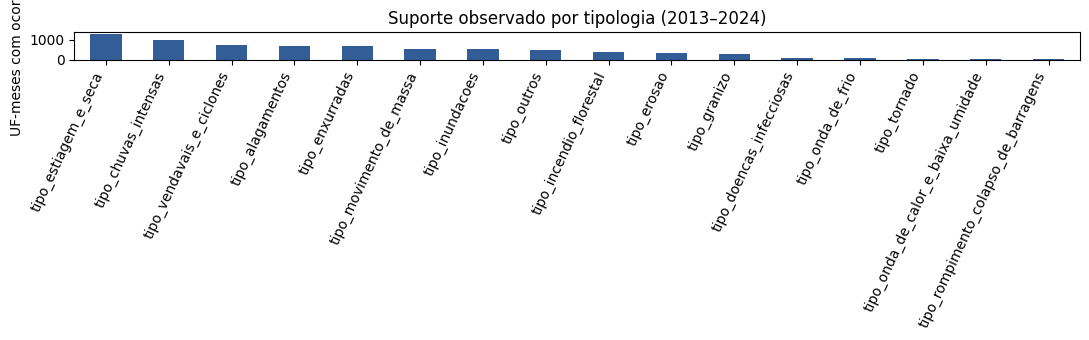

In [3]:
s=df.groupby('uf')[TIPOS].agg(lambda z:(z>0).sum()).T
fig,ax=plt.subplots(figsize=(11,3.5));s.sum(axis=1).sort_values(ascending=False).plot.bar(ax=ax,color='#335d96');ax.set_ylabel('UF-meses com ocorrência');ax.set_title('Suporte observado por tipologia (2013–2024)');plt.xticks(rotation=65,ha='right');plt.tight_layout();plt.show()

## 3. Diagnóstico ADF/KPSS

ADF testa **H₀: raiz unitária**; KPSS testa **H₀: estacionariedade**. Não rejeitar KPSS é compatível com estacionariedade, não prova sua existência. Calculamos os testes nas séries já transformadas e marcamos a ausência de suporte sem fabricar p-valores. A escolha de manter a transformação log-diferença busca coerência entre metodologias.

In [4]:
from statsmodels.tsa.stattools import adfuller, kpss

def diagnostico_estacionariedade(df, apenas_dependente=False):
    linhas=[]
    for periodo, limite in [('Pré','2020-01'),('Total','2024-12')]:
        d=df[df.mes_ano<=limite]
        for uf,g in d.groupby('uf'):
            cols=['y'] if apenas_dependente else ['y']+['x_'+tipo for tipo in TIPOS]
            for col in cols:
                v=g[col].dropna().to_numpy(float)
                rec={'periodo':periodo,'uf':uf,'serie':col,'n':len(v)}
                if len(v)<20 or np.ptp(v)<1e-10:
                    rec.update(p_ADF=np.nan,p_KPSS=np.nan,status='constante ou sem suporte');linhas.append(rec);continue
                try:
                    with warnings.catch_warnings(record=True) as w_adf:
                        warnings.simplefilter('always')
                        rec['p_ADF']=float(adfuller(v,regression='c',autolag='BIC')[1])
                    rec['avisos_ADF']=len(w_adf)
                except Exception as exc:rec['p_ADF']=np.nan;rec['erro_ADF']=type(exc).__name__
                try:
                    with warnings.catch_warnings(record=True) as w:
                        warnings.simplefilter('always')
                        rec['p_KPSS']=float(kpss(v,regression='c',nlags='auto')[1])
                    rec['avisos_KPSS']=len(w)
                except Exception as exc:rec['p_KPSS']=np.nan;rec['erro_KPSS']=type(exc).__name__
                a,k=rec['p_ADF'],rec['p_KPSS']
                rec['status']=('compatível com estacionariedade' if a<.05 and k>=.05 else
                    'sinais contrários' if a>=.05 and k<.05 else 'inconclusivo/divergente') if np.isfinite(a) and np.isfinite(k) else 'inconclusivo/sem teste'
                linhas.append(rec)
    return pd.DataFrame(linhas)

In [5]:
est=diagnostico_estacionariedade(df)
print('Séries avaliadas:',len(est));display(est.query("serie=='y'").groupby(['periodo','status']).size().rename('n').reset_index())
print('Séries com ADF/KPSS indisponível:',int(est.p_ADF.isna().sum()),int(est.p_KPSS.isna().sum()))
# Diagnósticos reproduzidos exclusivamente no notebook: preservamos as fontes históricas.

Séries avaliadas: 918


,periodo,status,n
0,Pré,compatível com estacionariedade,16
1,Pré,inconclusivo/divergente,10
2,Pré,sinais contrários,1
3,Total,compatível com estacionariedade,24
4,Total,inconclusivo/divergente,2
5,Total,sinais contrários,1


Séries com ADF/KPSS indisponível: 231 418


## 4. Especificação e estimação dos testes de Granger

Para cada UF, período e tipologia, testamos p=1,…,6 em **amostra comum de seis defasagens** e escolhemos p pelo BIC. Em cada regressão, `Y_t` contém intercepto, 11 indicadores de mês, `Y_{t−1},…,Y_{t−p}` e `X_{t−1},…,X_{t−p}`. A hipótese nula do F conjunto é \(H_0: \gamma_1=\cdots=\gamma_p=0\). A seleção não utiliza p-valores.

**Estimabilidade:** uma tipologia sem variação ou um desenho sem posto completo é marcada como não estimável. Isso não equivale a `p>0,05`. O ajuste BH usa a família de 16 tipologias por UF×período, preservando posições de não estimáveis como 1 apenas no cálculo do ajuste (sem reportar p observado).

In [6]:
def bh(df,groupcols,pcol='p',outcol='q_bh'):
    # Família planejada de 16 tipologias por UF×período (ou endpoint DLM).
    # Ausência de estimativa nunca é interpretada como p observado; um p=1
    # apenas ocupa a posição planejada para tornar o ajuste conservador.
    df[outcol]=np.nan
    for _,inds in df.groupby(groupcols,sort=False,dropna=False).groups.items():
        ps=df.loc[inds,pcol].to_numpy(float)
        assert len(ps)<=16, f'Família deveria ter até 16 tipologias, recebeu {len(ps)} para {groupcols}'
        full=np.r_[np.nan_to_num(ps,nan=1.0).clip(0,1),np.ones(16-len(ps))]
        q=multipletests(full,method='fdr_bh')[1][:len(ps)]
        q[~np.isfinite(ps)]=np.nan
        df.loc[inds,outcol]=q
    df['rejeicao_nominal']=df[pcol].lt(.05) & df[pcol].notna()
    df['rejeicao_bh']=df[outcol].lt(.05) & df[outcol].notna()
    return df

def granger(df):
    records=[];diags=[]
    for periodo,stop in [('Pré','2020-01'),('Total','2024-12')]:
        for uf,g in df[df.mes_ano<=stop].groupby('uf',sort=True):
            g=g.reset_index(drop=True);y=g['y'].to_numpy(float)
            for tipo in TIPOS:
                x=g['x_'+tipo].to_numpy(float)
                # Escolha p por BIC, utilizando amostra comum de pmax=6 em cada UF×recorte.
                pmax=6;t=np.arange(1+pmax,len(y));Y=y[t]; dummies=(g['mes'].to_numpy()[t,None]==np.arange(2,13)[None,:]).astype(float)
                if len(t)<30 or np.ptp(x[1:])<1e-12:
                    records.append(dict(uf=uf,periodo=periodo,tipologia=tipo,status='exposição transformada constante',n_eff=len(t),p_lags=np.nan));continue
                fits=[]
                for p in range(1,pmax+1):
                    X=np.column_stack([np.ones(len(t)),dummies]+[y[t-j] for j in range(1,p+1)]+[x[t-j] for j in range(1,p+1)])
                    if np.linalg.matrix_rank(X)!=X.shape[1] or not np.isfinite(X).all():continue
                    beta,*_=np.linalg.lstsq(X,Y,rcond=None);e=Y-X@beta;RSS=e@e
                    if RSS<=0:continue
                    bic=len(Y)*np.log(RSS/len(Y))+X.shape[1]*np.log(len(Y))
                    fits.append((bic,p,X,beta,e,RSS))
                if not fits:
                    records.append(dict(uf=uf,periodo=periodo,tipologia=tipo,status='sem modelo de posto completo na grade',n_eff=len(t),p_lags=np.nan));continue
                bic,p,X,beta,e,RSS=min(fits,key=lambda z:(z[0],z[1]));dof=len(Y)-X.shape[1];j0=X.shape[1]-p
                # F conjunto para H0: coeficientes de x_{t-1..t-p}=0, no modelo BIC selecionado.
                X0=X[:,:j0];b0=np.linalg.lstsq(X0,Y,rcond=None)[0];e0=Y-X0@b0;RSS0=e0@e0
                F=max(0,(RSS0-RSS)/p)/(RSS/dof);pv=float(stats.f.sf(F,p,dof))
                lb=float(acorr_ljungbox(e,lags=[min(12,max(3,len(e)//6))],return_df=True)['lb_pvalue'].iloc[0])
                records.append(dict(uf=uf,periodo=periodo,tipologia=tipo,status='estimado',n_eff=len(t),p_lags=p,criterio='BIC (lags 1..6; amostra comum)',BIC=bic,F=F,df_num=p,df_den=dof,p=pv,ljungbox_p=lb,diagnostico='sem rejeição LB nominal' if lb>=.05 else 'autocorrelação residual LB nominal',n_positivos=int((g[tipo]>0).sum())))
    o=pd.DataFrame(records);bh(o,['periodo','uf']);o.to_csv(OUT/'granger_aplicacoes.csv',index=False,encoding='utf-8-sig');o[o.rejeicao_nominal].to_csv(OUT/'granger_rejeicoes_nominais.csv',index=False,encoding='utf-8-sig');o[o.rejeicao_bh].to_csv(OUT/'granger_rejeicoes_bh.csv',index=False,encoding='utf-8-sig');return o

In [7]:
inicio=time.perf_counter(); g=granger(df)
assert len(g)==864 and g.groupby(['periodo','uf']).size().eq(16).all()
print(f'Granger executado em {time.perf_counter()-inicio:.1f}s')
print(g.status.value_counts().to_string())
print('Nominais:',int(g.rejeicao_nominal.sum()),'| Após BH:',int(g.rejeicao_bh.sum()))

Granger executado em 2.0s
status
estimado                                 627
exposição transformada constante         227
sem modelo de posto completo na grade     10
Nominais: 45 | Após BH: 14


## 5. Resíduos: Ljung–Box e magnitude da autocorrelação

**Ljung–Box H₀:** não há autocorrelação residual até as defasagens testadas. `p_LB<0,05` significa indício de autocorrelação; **não significa que a regressão não possa ser ajustada**, mas exige cautela com o teste F clássico. Não rejeitar o LB não prova ausência de correlação. Calculamos também ACF(1), maior autocorrelação absoluta entre as defasagens 1–12 e Durbin–Watson, para distinguir teste de intensidade.

In [8]:
from statsmodels.tsa.stattools import acf
from statsmodels.stats.stattools import durbin_watson

def auditoria_granger(data):
    hist=pd.read_csv(OUT/'granger_aplicacoes.csv')
    rows=[]
    for item in hist.itertuples(index=False):
        if item.status!='estimado':continue
        g=data[(data.uf==item.uf)&(data.mes_ano<=('2020-01' if item.periodo=='Pré' else '2024-12'))].reset_index(drop=True)
        y=g.y.to_numpy(float);x=g['x_'+item.tipologia].to_numpy(float);n=len(y)
        ti=np.arange(7,n);p=int(item.p_lags)
        Y=y[ti];dum=(g.mes.to_numpy()[ti,None]==np.arange(2,13)[None,:]).astype(float)
        X=np.column_stack([np.ones(len(ti)),dum]+[y[ti-j] for j in range(1,p+1)]+[x[ti-j] for j in range(1,p+1)])
        b=np.linalg.lstsq(X,Y,rcond=None)[0];e=Y-X@b
        lag=min(12,max(3,len(e)//6));corr=acf(e,nlags=lag,fft=True)[1:]
        lb=float(acorr_ljungbox(e,lags=[lag],return_df=True)['lb_pvalue'].iloc[0])
        rows.append({'uf':item.uf,'periodo':item.periodo,'tipologia':item.tipologia,
         'K_Granger':p,'p_Granger':float(item.p),'q_BH_Granger':float(item.q_bh),
         'rejeita_BH':bool(item.rejeicao_bh),'n_residuos':len(e),'lag_Ljung_Box':lag,
         'p_Ljung_Box':lb, 'acf1':float(corr[0]),'maior_acf_absoluta_1a12':float(np.max(np.abs(corr))),
         'limite_heuristico_acf':float(1.96/np.sqrt(len(e))),
         'n_lags_acf_acima_limite':int((np.abs(corr)>1.96/np.sqrt(len(e))).sum()),
         'dw':float(durbin_watson(e))})
    out=pd.DataFrame(rows)
    out.to_csv(AUD/'granger_autocorrelacao_intensidade.csv',index=False,encoding='utf-8-sig')
    return out

In [9]:
diag=auditoria_granger(df)
assert len(diag)==int(g.status.eq('estimado').sum())
S=diag[diag.rejeita_BH].copy()
print('BH=',len(S),'| sem rejeição do LB=',int((S.p_Ljung_Box>=.05).sum()),'| com rejeição=',int((S.p_Ljung_Box<.05).sum()))
display(S[['uf','periodo','tipologia','K_Granger','p_Granger','q_BH_Granger','p_Ljung_Box','maior_acf_absoluta_1a12']].sort_values(['periodo','uf']).round(6))

BH= 14 | sem rejeição do LB= 12 | com rejeição= 2


,uf,periodo,tipologia,K_Granger,p_Granger,q_BH_Granger,p_Ljung_Box,maior_acf_absoluta_1a12
9,AL,Pré,tipo_alagamentos,1,0.007469,0.039837,0.274391,0.250825
10,AL,Pré,tipo_chuvas_intensas,1,0.011352,0.045408,0.310762,0.250439
11,AL,Pré,tipo_enxurradas,1,0.007469,0.039837,0.274391,0.250825
14,AL,Pré,tipo_inundacoes,1,0.007469,0.039837,0.274391,0.250825
97,MG,Pré,tipo_chuvas_intensas,3,0.000370,0.005921,0.802680,0.200917
128,MT,Pré,tipo_doencas_infecciosas,3,0.001060,0.016960,0.727862,0.206434
140,PA,Pré,tipo_alagamentos,2,0.001274,0.020376,0.681278,0.202592
164,PE,Pré,tipo_enxurradas,1,0.000686,0.010977,0.326433,0.209037
179,PI,Pré,tipo_outros,4,0.000293,0.004681,0.393329,0.172692
203,RN,Pré,tipo_chuvas_intensas,4,0.000128,0.002048,0.775986,0.172772


## 6. Resultados e visualizações

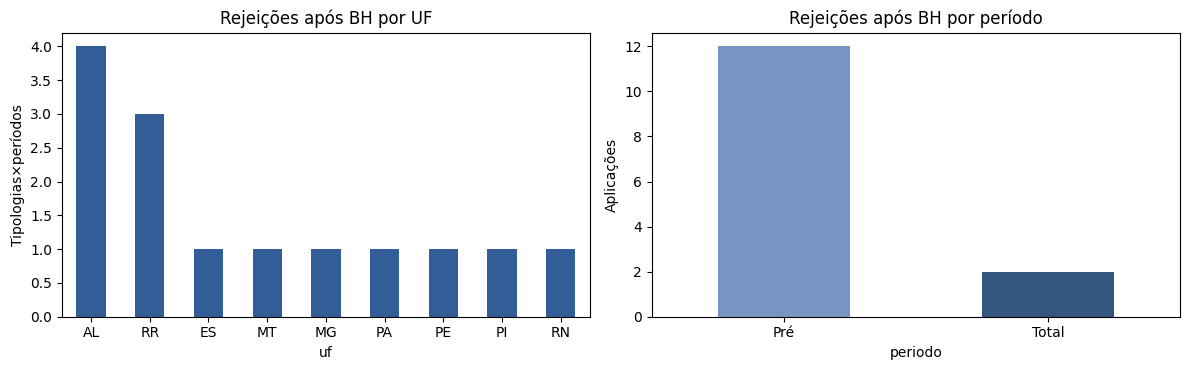

,uf,periodo,tipologia,p_lags,p,q_bh,ljungbox_p
0,AL,Pré,tipo_alagamentos,1.0,7.469455e-03,3.983709e-02,0.274391
1,AL,Pré,tipo_chuvas_intensas,1.0,1.135188e-02,4.540753e-02,0.310762
2,AL,Pré,tipo_enxurradas,1.0,7.469455e-03,3.983709e-02,0.274391
3,AL,Pré,tipo_inundacoes,1.0,7.469455e-03,3.983709e-02,0.274391
4,MG,Pré,tipo_chuvas_intensas,3.0,3.700429e-04,5.920687e-03,0.802680
5,MT,Pré,tipo_doencas_infecciosas,3.0,1.059986e-03,1.695977e-02,0.727862
6,PA,Pré,tipo_alagamentos,2.0,1.273501e-03,2.037601e-02,0.681278
7,PE,Pré,tipo_enxurradas,1.0,6.860359e-04,1.097658e-02,0.326433
8,PI,Pré,tipo_outros,4.0,2.925606e-04,4.680970e-03,0.393329
9,RN,Pré,tipo_chuvas_intensas,4.0,1.280114e-04,2.048182e-03,0.775986


In [10]:
sig=g[g.rejeicao_bh].copy(); assert len(sig)==14
fig,axs=plt.subplots(1,2,figsize=(12,3.8))
sig.groupby('uf').size().sort_values(ascending=False).plot.bar(ax=axs[0],color='#335d96');axs[0].set_title('Rejeições após BH por UF');axs[0].set_ylabel('Tipologias×períodos');axs[0].tick_params(axis='x',rotation=0)
(g.groupby('periodo').rejeicao_bh.sum().reindex(['Pré','Total'])).plot.bar(ax=axs[1],color=['#7895c4','#345680']);axs[1].set_title('Rejeições após BH por período');axs[1].set_ylabel('Aplicações');axs[1].tick_params(axis='x',rotation=0)
plt.tight_layout();plt.show()
display(sig[['uf','periodo','tipologia','p_lags','p','q_bh','ljungbox_p']].sort_values(['periodo','uf']).reset_index(drop=True))

## 7. Como interpretar e o que fica em aberto?

São **14 rejeições BH locais**, das quais **12 não rejeitam Ljung–Box** e **duas (Alagamentos/RR, pré e total) rejeitam**. As rejeições indicam ganho preditivo de defasagens climáticas *na especificação considerada*. Não há identificação causal e a escolha de p por BIC não foi incorporada formalmente ao F. As famílias BH são locais, não uma correção global sobre os 864 testes; os dois períodos são sobrepostos.

**Saídas reproduzíveis:** `outputs/tables/revisao_estadual_20261019/granger_aplicacoes.csv`, `granger_rejeicoes_bh.csv`, `granger_rejeicoes_nominais.csv`, mais `outputs/tables/auditoria_metodologica_20261020/granger_autocorrelacao_intensidade.csv`.